# OKKIO Loyalty Analytics – Phân tích hội viên và dự báo khả năng ngừng quay lại

Notebook dành cho Google Colab, sử dụng file `OKKIO_loyalty_log_cleaned.xlsx`.

## Mục tiêu phân tích
1. Kiểm tra dữ liệu và mô tả hoạt động loyalty.
2. Tạo bộ chỉ số RFM và phân khúc hội viên bằng K-Means.
3. Xây dựng mô hình dự báo hội viên không quay lại trong 90 ngày tiếp theo (XGBoost và LightGBM).
4. Diễn giải mô hình bằng SHAP.
5. Phân tích thời gian đến trạng thái ngừng quay lại bằng Kaplan–Meier.

## Quy ước nghiên cứu
- Đơn vị phân tích chính: `Mã hội viên`.
- Không sử dụng sheet danh bạ có số điện thoại/tên thật.
- Giữ hóa đơn 0 đồng; tách biến để đánh giá riêng, không mặc định xem là doanh thu.
- Không tự ý loại các hội viên nằm trong `TK_can_xem_xet`; chỉ gắn cờ và có thể chạy phân tích độ nhạy.
- Mốc dự báo mặc định: 30/06/2026; quan sát 90 ngày tiếp theo đến 28/09/2026. Mốc này có đủ thời gian theo dõi trong dữ liệu hiện tại.
- Định nghĩa nhãn mô hình: `churn_90d = 1` nếu hội viên không có hóa đơn nào trong 90 ngày sau mốc dự báo; ngược lại bằng 0. Đây là định nghĩa vận hành phục vụ nghiên cứu, không khẳng định khách đã rời bỏ vĩnh viễn.
- Mọi kết quả phụ thuộc vào dữ liệu loyalty được cung cấp và cần diễn giải đúng phạm vi mẫu.

## 1. Cài đặt thư viện và nạp dữ liệu
Chạy cell cài đặt một lần. Khi được hỏi, tải lên file Excel gốc.

In [1]:
!pip -q install openpyxl scikit-learn xgboost lightgbm shap lifelines imbalanced-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, precision_recall_curve,
    RocCurveDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

uploaded = files.upload()
xlsx_path = next((name for name in uploaded if name.lower().endswith(".xlsx")), None)
if xlsx_path is None:
    raise ValueError("Vui lòng tải lên file .xlsx")
print("Đã nạp:", xlsx_path)

xls = pd.ExcelFile(xlsx_path)
print("Các sheet:", xls.sheet_names)

tx = pd.read_excel(xlsx_path, sheet_name="Giao_dich")
red = pd.read_excel(xlsx_path, sheet_name="Doi_diem")
flagged = pd.read_excel(xlsx_path, sheet_name="TK_can_xem_xet")
excluded = pd.read_excel(xlsx_path, sheet_name="TK_quan_bi_loai")
nonstore = pd.read_excel(xlsx_path, sheet_name="Don_ngoai_cua_hang")

# Chuẩn hóa kiểu dữ liệu cơ bản
tx["Thời gian"] = pd.to_datetime(tx["Thời gian"], errors="coerce")
red["Thời gian"] = pd.to_datetime(red["Thời gian"], errors="coerce")
tx["Tiền chi tiêu (VND)"] = pd.to_numeric(tx["Tiền chi tiêu (VND)"], errors="coerce").fillna(0)
tx["Điểm cộng"] = pd.to_numeric(tx["Điểm cộng"], errors="coerce").fillna(0)
red["Điểm"] = pd.to_numeric(red["Điểm"], errors="coerce").fillna(0)

# Mã hội viên là khóa định danh, không dùng tên/số điện thoại
tx = tx.dropna(subset=["Mã hội viên", "Thời gian"]).copy()
red = red.dropna(subset=["Mã hội viên", "Thời gian"]).copy()

DATA_END = tx["Thời gian"].max().normalize()
print("Giao dịch:", tx.shape, "| Hội viên:", tx["Mã hội viên"].nunique())
print("Thời gian:", tx["Thời gian"].min(), "->", tx["Thời gian"].max())
print("Nhật ký đổi điểm:", red.shape, "| Hội viên:", red["Mã hội viên"].nunique())
print("Ngày cuối dữ liệu giao dịch:", DATA_END.date())

Saving OKKIO_loyalty_log_cleaned.xlsx to OKKIO_loyalty_log_cleaned.xlsx
Đã nạp: OKKIO_loyalty_log_cleaned.xlsx
Các sheet: ['Tong_quan', 'Giao_dich', 'Doi_diem', 'TK_quan_bi_loai', 'TK_can_xem_xet', 'Don_ngoai_cua_hang', 'Danh_ba_hoi_vien']
Giao dịch: (46761, 15) | Hội viên: 5984
Thời gian: 2025-04-10 14:10:00 -> 2026-10-06 21:08:27
Nhật ký đổi điểm: (2191, 8) | Hội viên: 607
Ngày cuối dữ liệu giao dịch: 2026-10-06


## 2. Kiểm tra chất lượng và mô tả dữ liệu

,missing,missing_pct,n_unique
ID giao dịch,0,0.00,46761
Mã hội viên,0,0.00,5984
Thời gian,0,0.00,46721
Ngày,0,0.00,540
Giờ,0,0.00,18
Tháng,0,0.00,19
Chi nhánh,0,0.00,9
Mã cửa hàng,0,0.00,7
Tiền chi tiêu (VND),0,0.00,539
Điểm cộng,0,0.00,448


ID giao dịch trùng: 0
Dòng giao dịch trùng toàn bộ: 0
Hóa đơn 0 đồng: 7725
Hóa đơn âm: 0
Hội viên có giao dịch: 5984
Chi nhánh:


,Số hóa đơn
Chi nhánh,
Thảo Điền,15225
Duy Tân,11957
Tự Do,7357
Bảo Tàng Mỹ Thuật,5690
Phú Mỹ Hưng,1842
Nguyễn Siêu,1784
Lê Lợi,1720
Vinmec,1184
Điện Biên Phủ,2


,Tháng,so_hoa_don,doanh_thu,so_hoi_vien,hoa_don_0d
0,2025-04,1332,123305800,452,306
1,2025-05,1951,187571100,593,415
2,2025-06,1993,183995750,585,527
3,2025-07,2048,184743250,603,567
4,2025-08,2178,184724750,739,496
5,2025-09,1986,164296000,626,520
6,2025-10,2326,197993700,816,460
7,2025-11,2519,239118700,1036,356
8,2025-12,2869,271914350,1132,432
9,2026-01,2941,270747850,1056,419


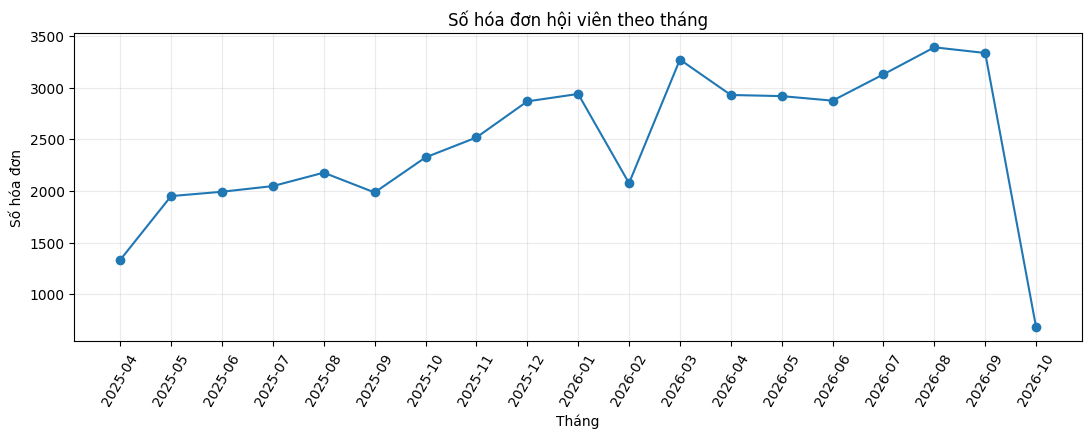

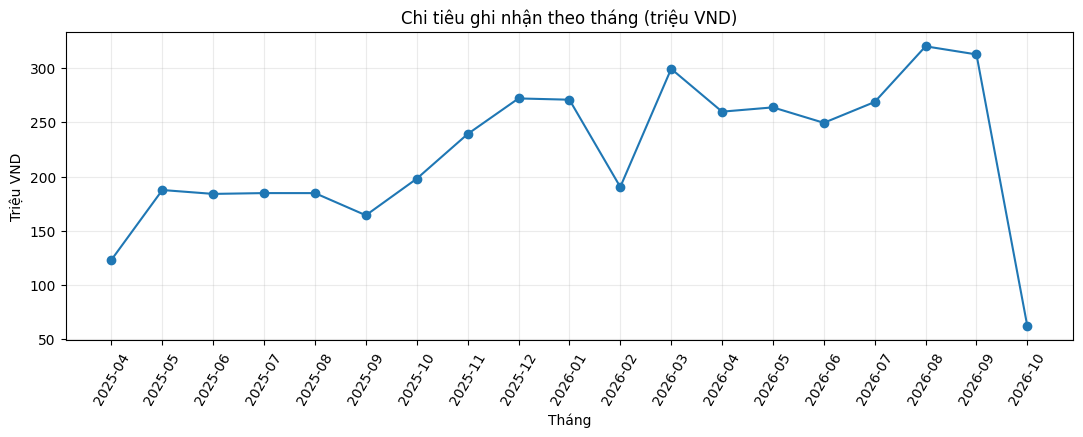

In [3]:
quality = pd.DataFrame({
    "missing": tx.isna().sum(),
    "missing_pct": (tx.isna().mean()*100).round(2),
    "n_unique": tx.nunique()
})
display(quality)

print("ID giao dịch trùng:", tx["ID giao dịch"].duplicated().sum())
print("Dòng giao dịch trùng toàn bộ:", tx.duplicated().sum())
print("Hóa đơn 0 đồng:", int((tx["Tiền chi tiêu (VND)"] == 0).sum()))
print("Hóa đơn âm:", int((tx["Tiền chi tiêu (VND)"] < 0).sum()))
print("Hội viên có giao dịch:", tx["Mã hội viên"].nunique())
print("Chi nhánh:")
display(tx["Chi nhánh"].value_counts().rename("Số hóa đơn").to_frame())

monthly = tx.groupby("Tháng").agg(
    so_hoa_don=("ID giao dịch", "nunique"),
    doanh_thu=("Tiền chi tiêu (VND)", "sum"),
    so_hoi_vien=("Mã hội viên", "nunique"),
    hoa_don_0d=("HĐ 0đ", "sum")
).reset_index()
display(monthly)

plt.figure(figsize=(13,4))
plt.plot(monthly["Tháng"], monthly["so_hoa_don"], marker="o")
plt.xticks(rotation=60)
plt.title("Số hóa đơn hội viên theo tháng")
plt.xlabel("Tháng"); plt.ylabel("Số hóa đơn"); plt.grid(alpha=.25); plt.show()

plt.figure(figsize=(13,4))
plt.plot(monthly["Tháng"], monthly["doanh_thu"]/1e6, marker="o")
plt.xticks(rotation=60)
plt.title("Chi tiêu ghi nhận theo tháng (triệu VND)")
plt.xlabel("Tháng"); plt.ylabel("Triệu VND"); plt.grid(alpha=.25); plt.show()

## 3. Tạo biến hội viên từ giao dịch và đổi điểm
RFM sử dụng tất cả hóa đơn hội viên để đo tần suất; chi tiêu bằng tổng tiền chi tiêu thực tế ghi nhận. Hóa đơn 0 đồng không đóng góp vào Monetary nhưng được đếm riêng.

In [4]:
# Tạo các biến giao dịch tổng hợp theo hội viên
tx["is_zero_bill"] = (tx["Tiền chi tiêu (VND)"] == 0).astype(int)
tx["is_paid_bill"] = (tx["Tiền chi tiêu (VND)"] > 0).astype(int)
tx["is_discount_used"] = pd.to_numeric(tx["Có dùng mã giảm giá"], errors="coerce").fillna(0).astype(int)

cust = tx.groupby("Mã hội viên").agg(
    first_purchase=("Thời gian", "min"),
    last_purchase=("Thời gian", "max"),
    frequency=("ID giao dịch", "nunique"),
    monetary=("Tiền chi tiêu (VND)", "sum"),
    paid_frequency=("is_paid_bill", "sum"),
    zero_bill_count=("is_zero_bill", "sum"),
    discount_bill_count=("is_discount_used", "sum"),
    avg_bill=("Tiền chi tiêu (VND)", "mean"),
    median_bill=("Tiền chi tiêu (VND)", "median"),
    branch_count=("Chi nhánh", "nunique"),
    active_days=("Ngày", "nunique")
).reset_index()

# Tổng hợp nhật ký đổi điểm theo hội viên; điểm âm thường là đổi điểm
red_agg = red.groupby("Mã hội viên").agg(
    redemption_log_count=("Điểm", "size"),
    points_net=("Điểm", "sum"),
    points_redeemed=("Điểm", lambda x: -x[x < 0].sum()),
    manual_adjustment_count=("Loại nhật ký", lambda x: (x == "Thay đổi điểm bằng tay").sum()),
    redemption_count=("Loại nhật ký", lambda x: (x == "Người dùng đổi điểm").sum())
).reset_index()

cust = cust.merge(red_agg, on="Mã hội viên", how="left")
red_cols = ["redemption_log_count","points_net","points_redeemed",
            "manual_adjustment_count","redemption_count"]
cust[red_cols] = cust[red_cols].fillna(0)

# Cờ rà soát: chỉ dùng để nhận diện độ nhạy, không loại tự động
flag_ids = set(flagged["Mã hội viên"].dropna().astype(str))
cust["review_flag"] = cust["Mã hội viên"].astype(str).isin(flag_ids).astype(int)

# RFM snapshot tại ngày cuối dữ liệu
cust["recency_days"] = (DATA_END - cust["last_purchase"].dt.normalize()).dt.days
cust["tenure_days"] = (DATA_END - cust["first_purchase"].dt.normalize()).dt.days
cust["frequency"] = cust["frequency"].astype(int)
cust["monetary"] = cust["monetary"].astype(float)

display(cust.describe(include="all").T)
print("Số hội viên tổng hợp:", len(cust))
print("Hội viên gắn cờ có mã trong dữ liệu giao dịch:", int(cust["review_flag"].sum()))

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Mã hội viên,5984,5984,KH00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
first_purchase,5984,NaN,NaN,NaN,2026-01-02 06:55:34.442346496,2025-04-10 14:10:00,2025-08-26 10:38:33,2025-12-23 11:51:42,2026-05-14 11:17:03.750000128,2026-10-06 21:08:27,NaN
last_purchase,5984,NaN,NaN,NaN,2026-04-12 10:10:55.049799680,2025-04-12 11:39:48,2025-12-19 09:17:09.500000,2026-05-09 13:12:09,2026-08-23 13:48:59.500000,2026-10-06 21:08:27,NaN
frequency,5984.0,NaN,NaN,NaN,7.814338,1.0,1.0,2.0,4.0,446.0,25.085029
monetary,5984.0,NaN,NaN,NaN,707531.876671,0.0,130000.0,215000.0,525000.0,68233500.0,1989740.73661
paid_frequency,5984.0,NaN,NaN,NaN,6.523396,0.0,1.0,1.0,4.0,423.0,19.436757
zero_bill_count,5984.0,NaN,NaN,NaN,1.290943,0.0,0.0,0.0,0.0,299.0,13.405132
discount_bill_count,5984.0,NaN,NaN,NaN,1.468082,0.0,0.0,0.0,0.0,301.0,11.13227
avg_bill,5984.0,NaN,NaN,NaN,131719.25735,0.0,76666.666667,112500.0,155000.0,3600000.0,109762.78679
median_bill,5984.0,NaN,NaN,NaN,127841.439672,0.0,75000.0,108125.0,152500.0,3600000.0,110331.745917


Số hội viên tổng hợp: 5984
Hội viên gắn cờ có mã trong dữ liệu giao dịch: 38


## 4. Phân tích RFM và phân khúc K-Means
RFM gồm Recency (số ngày từ lần mua gần nhất), Frequency (số hóa đơn) và Monetary (tổng chi tiêu). Do phân phối thường lệch phải, notebook dùng `log1p` trước khi chuẩn hóa. Chọn số cụm dựa trên Silhouette Score; cần kết hợp diễn giải nghiệp vụ trước khi đặt tên phân khúc.

,k,inertia,silhouette
0,2,9417.478991,0.537433
1,3,7400.074847,0.387171
2,4,5790.911472,0.417975
3,5,4360.258181,0.430132
4,6,3681.506144,0.409379
5,7,3083.235562,0.388612
6,8,2720.758759,0.387979


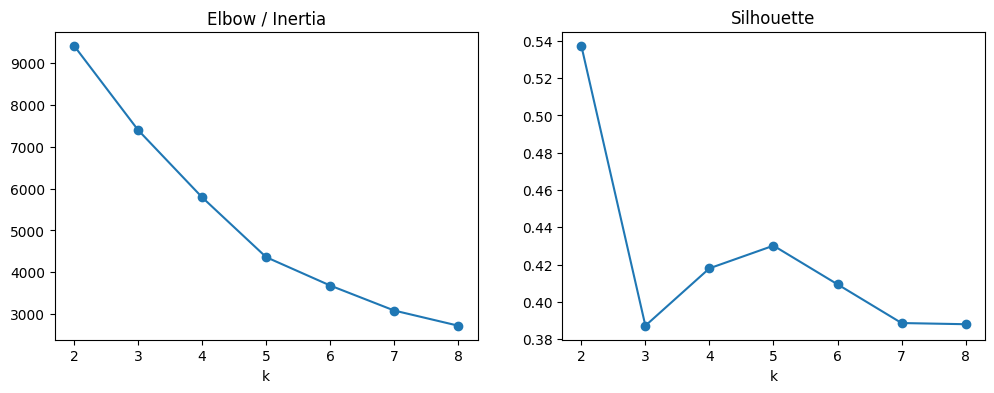

k được chọn tự động theo silhouette: 2


,cluster,members,recency_median,frequency_median,monetary_median,monetary_mean,zero_bill_mean,redemption_rate
0,0,4711,201.0,1.0,160000.0,2.295685e+05,0.053067,0.016557
1,1,1273,20.0,13.0,1355000.0,2.476334e+06,5.871956,0.402200


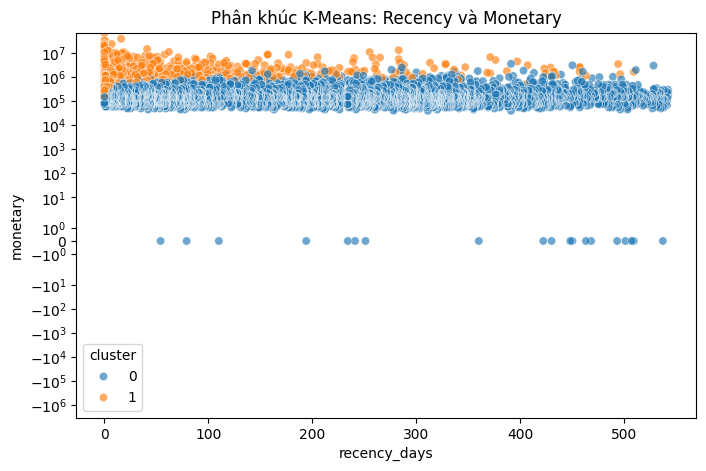

In [5]:
rfm = cust[["Mã hội viên","recency_days","frequency","monetary",
            "zero_bill_count","redemption_count","points_redeemed","review_flag"]].copy()

rfm_features = ["recency_days","frequency","monetary"]
X_rfm = rfm[rfm_features].copy()
X_rfm["recency_days"] = np.log1p(X_rfm["recency_days"].clip(lower=0))
X_rfm["frequency"] = np.log1p(X_rfm["frequency"].clip(lower=0))
X_rfm["monetary"] = np.log1p(X_rfm["monetary"].clip(lower=0))

scaler_rfm = StandardScaler()
X_scaled = scaler_rfm.fit_transform(X_rfm)

scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    scores.append({"k": k, "inertia": km.inertia_,
                   "silhouette": silhouette_score(X_scaled, labels)})
score_df = pd.DataFrame(scores)
display(score_df)

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(score_df.k, score_df.inertia, marker="o"); ax[0].set_title("Elbow / Inertia"); ax[0].set_xlabel("k")
ax[1].plot(score_df.k, score_df.silhouette, marker="o"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.show()

BEST_K = int(score_df.loc[score_df["silhouette"].idxmax(), "k"])
print("k được chọn tự động theo silhouette:", BEST_K)
kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=30)
rfm["cluster"] = kmeans.fit_predict(X_scaled)
cust = cust.merge(rfm[["Mã hội viên","cluster"]], on="Mã hội viên", how="left")

cluster_profile = cust.groupby("cluster").agg(
    members=("Mã hội viên","nunique"),
    recency_median=("recency_days","median"),
    frequency_median=("frequency","median"),
    monetary_median=("monetary","median"),
    monetary_mean=("monetary","mean"),
    zero_bill_mean=("zero_bill_count","mean"),
    redemption_rate=("redemption_count",lambda x:(x>0).mean())
).reset_index()
display(cluster_profile)

plt.figure(figsize=(8,5))
sns.scatterplot(data=cust, x="recency_days", y="monetary", hue="cluster", palette="tab10", alpha=.65)
plt.yscale("symlog"); plt.title("Phân khúc K-Means: Recency và Monetary"); plt.show()

## 5. Xây dựng nhãn churn 90 ngày và bộ đặc trưng dự báo
Để tránh dùng thông tin tương lai làm đặc trưng, mô hình chỉ dùng giao dịch và đổi điểm trước hoặc tại ngày snapshot. Nhãn được xác định bằng hoạt động giao dịch trong 90 ngày tiếp theo.

In [6]:
SNAPSHOT_DATE = pd.Timestamp("2026-06-30")
HORIZON_DAYS = 90
LABEL_END = SNAPSHOT_DATE + pd.Timedelta(days=HORIZON_DAYS)

if tx["Thời gian"].max() < LABEL_END:
    raise ValueError(f"Dữ liệu chưa đủ theo dõi đến {LABEL_END.date()}; cần giảm snapshot hoặc bổ sung dữ liệu.")

hist_tx = tx[tx["Thời gian"] <= SNAPSHOT_DATE].copy()
future_tx = tx[(tx["Thời gian"] > SNAPSHOT_DATE) &
               (tx["Thời gian"] <= LABEL_END)].copy()
hist_red = red[red["Thời gian"] <= SNAPSHOT_DATE].copy()

# Chỉ lấy hội viên đã phát sinh ít nhất một hóa đơn đến snapshot
base = hist_tx.groupby("Mã hội viên").agg(
    first_purchase=("Thời gian","min"),
    last_purchase=("Thời gian","max"),
    frequency=("ID giao dịch","nunique"),
    monetary=("Tiền chi tiêu (VND)","sum"),
    paid_frequency=("is_paid_bill","sum") if "is_paid_bill" in hist_tx.columns else ("ID giao dịch","size"),
    zero_bill_count=("HĐ 0đ","sum"),
    discount_bill_count=("Có dùng mã giảm giá","sum"),
    avg_bill=("Tiền chi tiêu (VND)","mean"),
    branch_count=("Chi nhánh","nunique"),
    active_days=("Ngày","nunique")
).reset_index()

base["recency_days"] = (SNAPSHOT_DATE - base["last_purchase"].dt.normalize()).dt.days
base["tenure_days"] = (SNAPSHOT_DATE - base["first_purchase"].dt.normalize()).dt.days

# Các cửa sổ hành vi gần snapshot
for days in [30, 60, 90, 180]:
    w = hist_tx[hist_tx["Thời gian"] > SNAPSHOT_DATE - pd.Timedelta(days=days)]
    agg = w.groupby("Mã hội viên").agg(
        **{f"bills_{days}d":("ID giao dịch","nunique"),
           f"spend_{days}d":("Tiền chi tiêu (VND)","sum"),
           f"zero_{days}d":("HĐ 0đ","sum")}
    ).reset_index()
    base = base.merge(agg, on="Mã hội viên", how="left")

base = base.fillna(0)

# Đổi điểm chỉ tính đến snapshot
if len(hist_red):
    ra = hist_red.groupby("Mã hội viên").agg(
        redemption_count=("Loại nhật ký", lambda x:(x=="Người dùng đổi điểm").sum()),
        points_redeemed=("Điểm", lambda x:-x[x<0].sum()),
        manual_adjustments=("Loại nhật ký", lambda x:(x=="Thay đổi điểm bằng tay").sum())
    ).reset_index()
    base = base.merge(ra, on="Mã hội viên", how="left")
else:
    base["redemption_count"] = 0
    base["points_redeemed"] = 0
    base["manual_adjustments"] = 0

for c in ["redemption_count","points_redeemed","manual_adjustments"]:
    base[c] = base[c].fillna(0)

future_active = set(future_tx["Mã hội viên"].unique())
base["churn_90d"] = (~base["Mã hội viên"].isin(future_active)).astype(int)

print("Snapshot:", SNAPSHOT_DATE.date(), "| Hết kỳ nhãn:", LABEL_END.date())
print("Cỡ mẫu:", len(base))
print("Tỷ lệ churn 90d:", round(base["churn_90d"].mean()*100,2), "%")
display(base["churn_90d"].value_counts().rename("n").to_frame())

Snapshot: 2026-06-30 | Hết kỳ nhãn: 2026-09-28
Cỡ mẫu: 4841
Tỷ lệ churn 90d: 74.26 %


,n
churn_90d,
1,3595
0,1246


## 6. Huấn luyện và đánh giá XGBoost, LightGBM
Dùng train/test stratified split để so sánh trên cùng một cohort snapshot. Vì chỉ có một mốc snapshot, đây chưa phải kiểm định ngoài thời gian nhiều kỳ; luận văn nên ghi rõ giới hạn này và bổ sung backtesting ở các snapshot khác nếu có dữ liệu đủ dài.

In [7]:
exclude_cols = ["Mã hội viên","first_purchase","last_purchase","churn_90d"]
feature_cols = [c for c in base.columns if c not in exclude_cols]
X = base[feature_cols].select_dtypes(include=[np.number]).copy()
y = base["churn_90d"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
scale_pos_weight = max(1.0, (y_train==0).sum()/max(1,(y_train==1).sum()))

models = {
    "XGBoost": XGBClassifier(
        n_estimators=450, max_depth=3, learning_rate=0.035,
        subsample=0.85, colsample_bytree=0.85,
        reg_lambda=2, min_child_weight=5,
        objective="binary:logistic", eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=450, max_depth=-1, num_leaves=15,
        learning_rate=0.03, subsample=0.85, colsample_bytree=0.85,
        reg_lambda=2, class_weight="balanced",
        random_state=RANDOM_STATE, verbosity=-1
    )
}

results, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]
    results.append({
        "model":name,
        "ROC_AUC":roc_auc_score(y_test,prob),
        "PR_AUC":average_precision_score(y_test,prob),
        "Accuracy":(pred==y_test).mean()
    })
    print("\n", name)
    print(classification_report(y_test,pred,digits=3))
    print("Confusion matrix:\n", confusion_matrix(y_test,pred))

model_scores = pd.DataFrame(results).sort_values("PR_AUC",ascending=False)
display(model_scores)


 XGBoost
              precision    recall  f1-score   support

           0      0.703     0.478     0.569       312
           1      0.837     0.930     0.881       899

    accuracy                          0.813      1211
   macro avg      0.770     0.704     0.725      1211
weighted avg      0.802     0.813     0.800      1211

Confusion matrix:
 [[149 163]
 [ 63 836]]

 LightGBM
              precision    recall  f1-score   support

           0      0.594     0.628     0.611       312
           1      0.868     0.851     0.860       899

    accuracy                          0.794      1211
   macro avg      0.731     0.740     0.735      1211
weighted avg      0.798     0.794     0.795      1211

Confusion matrix:
 [[196 116]
 [134 765]]


,model,ROC_AUC,PR_AUC,Accuracy
0,XGBoost,0.839635,0.924278,0.813377
1,LightGBM,0.827048,0.918950,0.793559


## 7. SHAP – giải thích mô hình
SHAP được tính cho mô hình có PR-AUC cao nhất trên tập train. Đây là giải thích mức độ đóng góp của đặc trưng vào dự báo của mô hình, không chứng minh quan hệ nhân quả.

Mô hình được chọn để giải thích: XGBoost


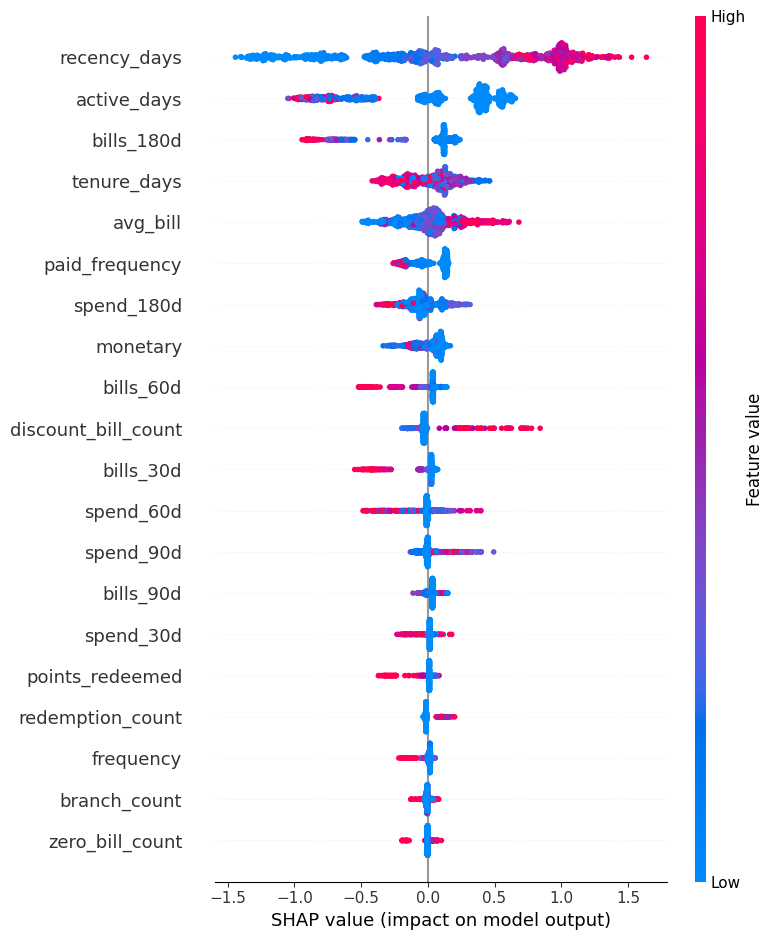

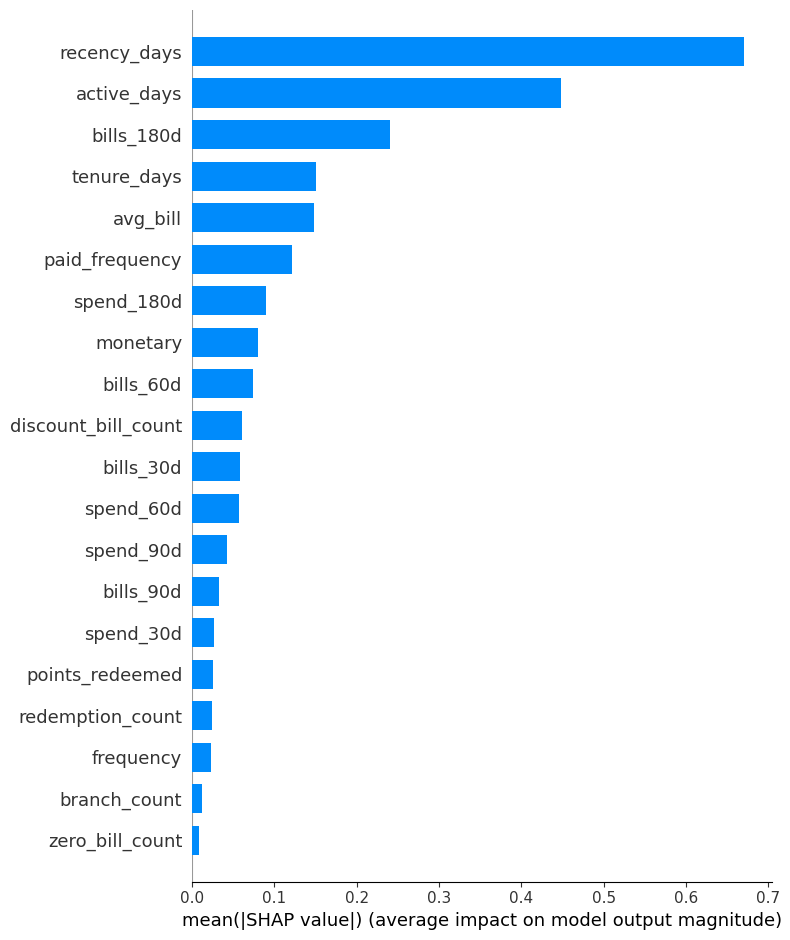

In [8]:
best_name = model_scores.iloc[0]["model"]
best_model = fitted[best_name]
print("Mô hình được chọn để giải thích:", best_name)

# Lấy mẫu để giảm thời gian tính toán trên Colab
X_shap = X_train.sample(min(1000, len(X_train)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)

# Tương thích đầu ra SHAP dạng list/array
if isinstance(shap_values, list):
    shap_plot_values = shap_values[-1]
else:
    shap_plot_values = shap_values

shap.summary_plot(shap_plot_values, X_shap, show=True)
shap.summary_plot(shap_plot_values, X_shap, plot_type="bar", show=True)

## 8. Kaplan–Meier: thời gian đến trạng thái ngừng quay lại
Định nghĩa vận hành: một hội viên được xem là có sự kiện churn khi đã qua 90 ngày kể từ hóa đơn cuối cùng mà không có hóa đơn mới, và mốc đó nằm trong thời gian quan sát. Nếu chưa đủ 90 ngày tính đến ngày cuối dữ liệu, quan sát bị kiểm duyệt phải (right-censored). Thời gian được tính từ hóa đơn đầu tiên đến ngày sự kiện hoặc ngày cuối dữ liệu.

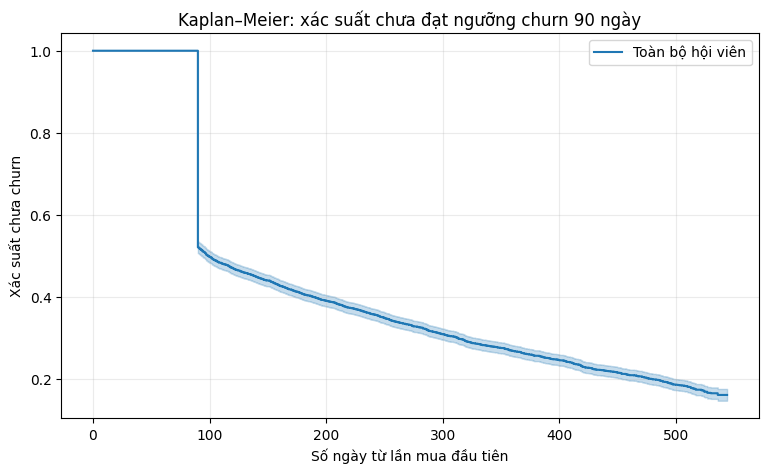

Số hội viên trong phân tích survival: 5984
Số sự kiện churn quan sát được: 3672
Tỷ lệ sự kiện: 61.36 %


In [9]:
!pip -q install lifelines
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

surv = tx.groupby("Mã hội viên").agg(
    first_purchase=("Thời gian","min"),
    last_purchase=("Thời gian","max"),
    frequency=("ID giao dịch","nunique"),
    monetary=("Tiền chi tiêu (VND)","sum")
).reset_index()

observation_end = tx["Thời gian"].max()
surv["churn_date"] = surv["last_purchase"] + pd.Timedelta(days=90)
surv["event_observed"] = (surv["churn_date"] <= observation_end).astype(int)
surv["end_date"] = np.where(
    surv["event_observed"].eq(1),
    surv["churn_date"].values,
    observation_end
)
surv["end_date"] = pd.to_datetime(surv["end_date"])
surv["duration_days"] = (surv["end_date"] - surv["first_purchase"]).dt.days.clip(lower=1)

kmf = KaplanMeierFitter()
kmf.fit(surv["duration_days"], event_observed=surv["event_observed"],
        label="Toàn bộ hội viên")
ax = kmf.plot_survival_function(figsize=(9,5))
ax.set_title("Kaplan–Meier: xác suất chưa đạt ngưỡng churn 90 ngày")
ax.set_xlabel("Số ngày từ lần mua đầu tiên")
ax.set_ylabel("Xác suất chưa churn")
ax.grid(alpha=.25)
plt.show()

print("Số hội viên trong phân tích survival:", len(surv))
print("Số sự kiện churn quan sát được:", int(surv["event_observed"].sum()))
print("Tỷ lệ sự kiện:", round(surv["event_observed"].mean()*100,2), "%")

## 9. Phân tích độ nhạy: loại hội viên gắn cờ và hóa đơn 0 đồng
Không loại dữ liệu ở phân tích chính. Phần này giúp kiểm tra xem kết quả RFM có thay đổi đáng kể nếu loại các hội viên được gắn cờ hoặc chỉ tính hóa đơn có chi tiêu dương.

In [10]:
# RFM sensitivity 1: chỉ tính hóa đơn chi tiêu dương
paid = tx[tx["Tiền chi tiêu (VND)"] > 0].copy()
paid_rfm = paid.groupby("Mã hội viên").agg(
    first_purchase=("Thời gian","min"),
    last_purchase=("Thời gian","max"),
    frequency=("ID giao dịch","nunique"),
    monetary=("Tiền chi tiêu (VND)","sum")
).reset_index()
paid_rfm["recency_days"] = (DATA_END - paid_rfm["last_purchase"].dt.normalize()).dt.days
display(paid_rfm[["recency_days","frequency","monetary"]].describe())

# So sánh profile hội viên gắn cờ và không gắn cờ
display(cust.groupby("review_flag").agg(
    members=("Mã hội viên","nunique"),
    recency_median=("recency_days","median"),
    frequency_median=("frequency","median"),
    monetary_median=("monetary","median"),
    zero_bill_median=("zero_bill_count","median")
))

,recency_days,frequency,monetary
count,5965.000000,5965.000000,5.965000e+03
mean,177.351215,6.544174,7.097855e+05
std,145.438152,19.464200,1.992506e+06
min,0.000000,1.000000,4.000000e+04
25%,44.000000,1.000000,1.300000e+05
50%,150.000000,1.000000,2.150000e+05
75%,291.000000,4.000000,5.250000e+05
max,542.000000,423.000000,6.823350e+07


,members,recency_median,frequency_median,monetary_median,zero_bill_median
review_flag,,,,,
0,5946,150.5,1.0,215000.0,0.0
1,38,3.5,234.5,3615950.0,11.5


In [11]:
# Độ nhạy định nghĩa churn theo các ngưỡng 60 / 90 / 120 ngày
horizon_sensitivity = []
for h in [60, 90, 120]:
    end_h = SNAPSHOT_DATE + pd.Timedelta(days=h)
    if tx["Thời gian"].max() < end_h:
        horizon_sensitivity.append({"horizon_days":h, "status":"Không đủ dữ liệu theo dõi"})
        continue
    fut = tx[(tx["Thời gian"] > SNAPSHOT_DATE) & (tx["Thời gian"] <= end_h)]
    active = set(fut["Mã hội viên"].unique())
    churn_rate = (~base["Mã hội viên"].isin(active)).mean()
    horizon_sensitivity.append({
        "horizon_days":h,
        "status":"Đủ dữ liệu",
        "churn_rate":churn_rate,
        "n_cohort":len(base)
    })
horizon_sensitivity = pd.DataFrame(horizon_sensitivity)
display(horizon_sensitivity)

,horizon_days,status,churn_rate,n_cohort
0,60,Đủ dữ liệu,0.784342,4841.0
1,90,Đủ dữ liệu,0.742615,4841.0
2,120,Không đủ dữ liệu theo dõi,NaN,NaN


## 10. Xuất kết quả
Các file xuất không chứa số điện thoại hoặc tên thật. Kiểm tra lại trước khi chia sẻ hoặc đưa dữ liệu lên kho mã nguồn công khai.

In [12]:
output_xlsx = "OKKIO_loyalty_analysis_outputs.xlsx"
with pd.ExcelWriter(output_xlsx, engine="openpyxl") as writer:
    cust.to_excel(writer, sheet_name="Customer_RFM_Cluster", index=False)
    cluster_profile.to_excel(writer, sheet_name="Cluster_Profile", index=False)
    base.to_excel(writer, sheet_name="Churn_Model_Data", index=False)
    model_scores.to_excel(writer, sheet_name="Model_Comparison", index=False)
    surv.to_excel(writer, sheet_name="Survival_Data", index=False)
    monthly.to_excel(writer, sheet_name="Monthly_Overview", index=False)
    score_df.to_excel(writer, sheet_name="KMeans_Scores", index=False)

files.download(output_xlsx)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Lưu ý khi đưa kết quả vào luận văn
- Không viết kết quả AUC, Silhouette, số cụm hoặc biến SHAP trước khi chạy notebook trên Colab.
- Churn 90 ngày là định nghĩa nghiên cứu; cần nêu rõ trong phần phương pháp và kiểm tra độ nhạy với ngưỡng 60/90/120 ngày.
- K-Means nhạy với cách chọn biến, biến đổi log và số cụm. Báo cáo cả tiêu chí định lượng và diễn giải từng cụm.
- Với mô hình dự báo, nên báo cáo ROC-AUC, PR-AUC, Precision, Recall, F1 và ma trận nhầm lẫn; đặc biệt chú ý mất cân bằng lớp.
- SHAP cho biết mô hình sử dụng biến nào để dự báo, không khẳng định biến đó gây ra churn.
- Dữ liệu hội viên không đại diện toàn bộ khách hàng OKKIO do chỉ gồm khách có cung cấp SĐT/được nhận diện trong hệ thống.
- Trước khi nộp luận văn, cần đối chiếu mọi số liệu trong bản thảo với kết quả chạy thực tế và lưu lại phiên bản dữ liệu, ngày chạy, tham số mô hình.

#Website

In [18]:
from google.colab import files
uploaded = files.upload()  # Chọn OKKIO_Loyalty_Website_Starter.zip

Saving OKKIO_Loyalty_Website_v2.zip to OKKIO_Loyalty_Website_v2.zip


In [19]:
import os, zipfile

zip_name = next((name for name in uploaded.keys() if name.lower().endswith(".zip")), None)
if zip_name is None:
    raise ValueError("Bạn chưa upload file ZIP source code website.")

extract_dir = "/content/okkio_website"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(extract_dir)

project_dir = os.path.join(extract_dir, "OKKIO_Loyalty_Website")
if not os.path.isdir(project_dir):
    # fallback: tìm app.py trong thư mục vừa giải nén
    candidates = []
    for root, dirs, filenames in os.walk(extract_dir):
        if "app.py" in filenames and "requirements.txt" in filenames:
            candidates.append(root)
    if not candidates:
        raise FileNotFoundError("Không tìm thấy app.py và requirements.txt trong ZIP.")
    project_dir = candidates[0]

os.chdir(project_dir)
print("Source code folder:", project_dir)
print("Files:", os.listdir(project_dir))

Source code folder: /content/okkio_website/OKKIO_Loyalty_Website
Files: ['requirements.txt', 'README.md', 'OKKIO_Loyalty_Website_v2.zip', 'app.py']


In [20]:
%pip install -q -r requirements.txt

In [23]:
import os
from getpass import getpass

# Tạo mật khẩu riêng cho website OKKIO
os.environ["OKKIO_APP_PASSWORD"] = getpass(
    "Nhập mật khẩu đăng nhập website OKKIO: "
)

print("Đã thiết lập mật khẩu thành công!")

Nhập mật khẩu đăng nhập website OKKIO: ··········
Đã thiết lập mật khẩu thành công!


In [24]:
import subprocess, time, os, signal

# Dừng Streamlit cũ nếu notebook đã chạy trước đó
subprocess.run("pkill -f 'streamlit run app.py' || true", shell=True)

log_path = "/content/okkio_streamlit.log"
streamlit_cmd = [
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.headless", "true"
]
streamlit_log = open(log_path, "w")
streamlit_process = subprocess.Popen(
    streamlit_cmd,
    cwd=project_dir,
    stdout=streamlit_log,
    stderr=subprocess.STDOUT
)
time.sleep(8)

if streamlit_process.poll() is not None:
    print(open(log_path).read())
    raise RuntimeError("Streamlit không khởi động được. Kiểm tra log ở trên.")

print("Streamlit đang chạy tại cổng 8501.")


Streamlit đang chạy tại cổng 8501.


In [25]:
import platform, urllib.request, re, subprocess, time, os, stat

cloudflared_path = "/content/cloudflared"
download_url = "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"

if not os.path.exists(cloudflared_path):
    urllib.request.urlretrieve(download_url, cloudflared_path)
    os.chmod(cloudflared_path, os.stat(cloudflared_path).st_mode | stat.S_IEXEC)

tunnel_process = subprocess.Popen(
    [cloudflared_path, "tunnel", "--url", "http://127.0.0.1:8501", "--no-autoupdate"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

public_url = None
start = time.time()
while time.time() - start < 90:
    line = tunnel_process.stdout.readline()
    if line:
        print(line.rstrip())
        match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
        if match:
            public_url = match.group(0)
            break
    if tunnel_process.poll() is not None:
        break

if public_url:
    print("\nWEBSITE OKKIO:", public_url)
    print("Mở URL trên bằng trình duyệt. Không chia sẻ URL nếu dữ liệu không được phép công khai.")
else:
    print("Chưa lấy được URL tự động. Xem log phía trên; nếu cần, chạy lại cell này.")


2026-11-26T05:04:50Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-26T05:04:50Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-26T05:04:53Z INF +--------------------------------------------------------------------------------------------+
2026-11-26T05:04:53Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-26T05:04:53Z INF |  https://alike-strain-enhancing-blonde.trycloudflare.c